# Long or cash backtest

This notebook reads saved out of sample predictions. Each positive signal is one trade: enter at the next bar open and exit at its close. The backtest charges one cost per side at entry and exit. Cost rates are illustrative and are not broker estimates.


In [1]:
# Load the saved strategy summaries and daily returns; no predictions are refit here.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == 'notebooks' else cwd
results_dir = project_root / 'results'
summary = pd.read_csv(results_dir / 'long_or_cash_backtest_summary.csv')
daily_returns = pd.read_csv(results_dir / 'long_or_cash_backtest_daily_returns.csv', parse_dates=['session_date'])
display(summary.sort_values(['ETF', 'model', 'cost_bps_per_side']).round(4))

,ETF,model,cost_bps_per_side,intervals,active_intervals,exposure_fraction,entries,exits,trade_events,one_way_turnover,entries_per_session,cumulative_cost_fraction_uncompounded,sessions,gross_cumulative_return,net_cumulative_return,maximum_drawdown,annualized_daily_sharpe
5,QQQ,Direction persistence baseline,0.0,23419,11705,0.4998,11705,11705,23410,23410.0,25.2263,0.0000,464,-0.2136,-0.2136,-0.2145,-1.6149
6,QQQ,Direction persistence baseline,1.0,23419,11705,0.4998,11705,11705,23410,23410.0,25.2263,2.3410,464,-0.2136,-0.9243,-0.9243,-18.4112
7,QQQ,Direction persistence baseline,2.5,23419,11705,0.4998,11705,11705,23410,23410.0,25.2263,5.8525,464,-0.2136,-0.9977,-0.9977,-41.6889
8,QQQ,Direction persistence baseline,5.0,23419,11705,0.4998,11705,11705,23410,23410.0,25.2263,11.7050,464,-0.2136,-1.0000,-1.0000,-63.9706
9,QQQ,Direction persistence baseline,10.0,23419,11705,0.4998,11705,11705,23410,23410.0,25.2263,23.4100,464,-0.2136,-1.0000,-1.0000,-74.6384
20,QQQ,LSTM,0.0,23419,16618,0.7096,16618,16618,33236,33236.0,35.8147,0.0000,464,0.1651,0.1651,-0.0656,1.0825
21,QQQ,LSTM,1.0,23419,16618,0.7096,16618,16618,33236,33236.0,35.8147,3.3236,464,0.1651,-0.9580,-0.9580,-20.7587
22,QQQ,LSTM,2.5,23419,16618,0.7096,16618,16618,33236,33236.0,35.8147,8.3090,464,0.1651,-0.9997,-0.9997,-42.3584
23,QQQ,LSTM,5.0,23419,16618,0.7096,16618,16618,33236,33236.0,35.8147,16.6180,464,0.1651,-1.0000,-1.0000,-55.2067
24,QQQ,LSTM,10.0,23419,16618,0.7096,16618,16618,33236,33236.0,35.8147,33.2360,464,0.1651,-1.0000,-1.0000,-60.7648


## How transaction costs change the XGBoost equity curve

This compares the growth of a hypothetical 1 unit invested with no cost and with a 1 bp cost on each side. It makes the cost sensitivity visible across the test period.

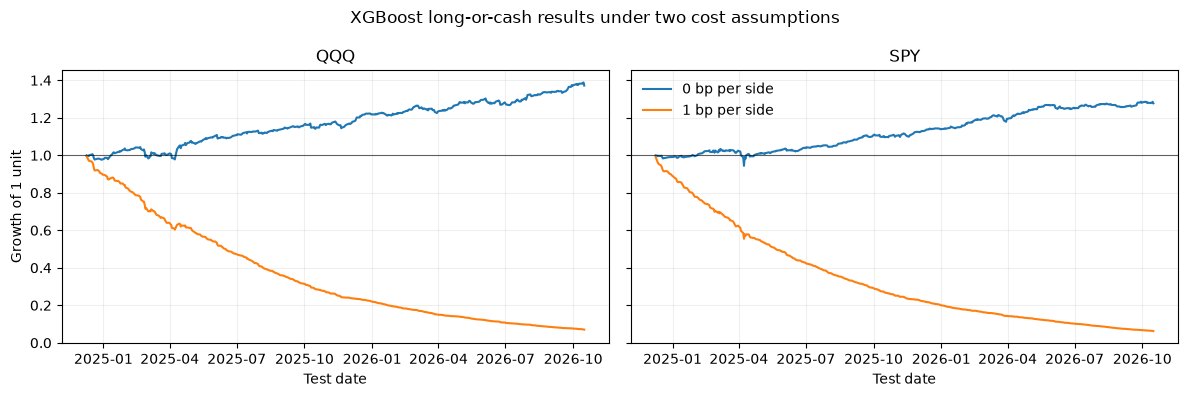

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, ticker in zip(axes, ['QQQ', 'SPY']):
    for cost_bps, color in [(0.0, 'tab:blue'), (1.0, 'tab:orange')]:
        # Each curve starts at 1 and compounds the saved daily net returns.
        series = daily_returns.loc[
            daily_returns['ETF'].eq(ticker)
            & daily_returns['model'].eq('XGBoost')
            & daily_returns['cost_bps_per_side'].eq(cost_bps)
        ].sort_values('session_date')
        growth = (1 + series['net_return']).cumprod()
        ax.plot(series['session_date'], growth, label=f'{cost_bps:g} bp per side', color=color)
    ax.axhline(1, color='black', linewidth=0.8, alpha=0.6)
    ax.set_title(ticker)
    ax.set_xlabel('Test date')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Growth of 1 unit')
axes[1].legend(frameon=False)
fig.suptitle('XGBoost long-or-cash results under two cost assumptions')
fig.tight_layout()
plt.show()

## Interpretation boundary

The summary is a historical sensitivity analysis on the shared out of sample timestamps. It assumes a signal from the completed bar can be executed at the next bar open; returns are measured from that open to the same bar close. Trading performance still depends on this bar level execution assumption and the per side cost scenario.